In [72]:
import numpy as np
import matplotlib.pyplot as plt

import cev_pricer
import importlib

importlib.reload(cev_pricer)
from cev_pricer import *

In [73]:
(F0, X, r, sigma, beta, T) = (10, 10, 0.05, 0.2, 0.5, 9/12)

payment_times = np.array([
    T + 0.2,
    T + 0.7,
    T + 1.1,
    T + 2.5,
    T + 3.6
])

option_type = "call"
swaption_type = "payer"

S0 = 11

n_time = 800
n_sim_option = 10_000
n_sim_swaption = 30_000
seed = 0

Nt = 250
NF = 200
NS = 200

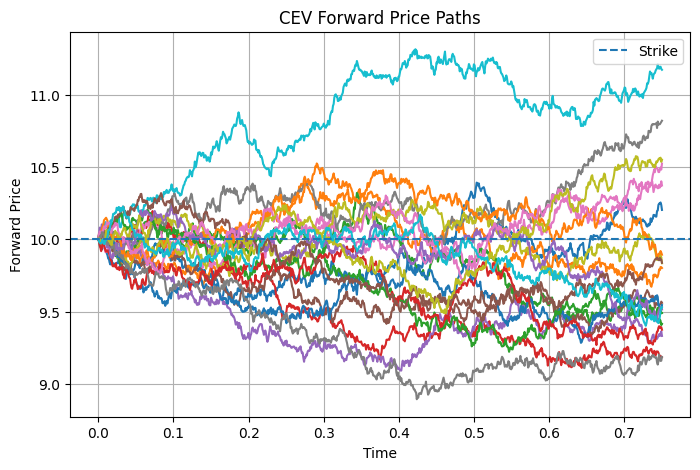

In [74]:
F_paths = cev_paths(
    F0=F0,
    sigma=sigma,
    beta=beta,
    T=T,
    n_time=n_time,
    n_sim=20,
    seed=seed
)

time_grid = np.linspace(0, T, n_time + 1)

plt.figure(figsize=(8, 5))

for i in range(F_paths.shape[0]):
    plt.plot(time_grid, F_paths[i])

plt.axhline(X, linestyle="--", label="Strike")

plt.xlabel("Time")
plt.ylabel("Forward Price")
plt.title("CEV Forward Price Paths")
plt.legend()
plt.grid()
plt.show()

In [75]:
price_option_analytical = cev_option_price_analytical(
    F0=F0,
    X=X,
    r=r,
    sigma=sigma,
    beta=beta,
    T=T,
    option_type=option_type
)

price_option_mc = cev_option_price_mc(
    F0=F0,
    X=X,
    r=r,
    sigma=sigma,
    beta=beta,
    T=T,
    n_time=n_time,
    n_sim=n_sim_option,
    option_type=option_type,
    seed=seed
)

price_option_cn = cev_option_price_cn(
    F0=F0,
    X=X,
    r=r,
    sigma=sigma,
    beta=beta,
    T=T,
    Nt=Nt,
    NF=NF,
    option_type=option_type
)

print(f"Analytical Option Price     : {price_option_analytical:.6f}")
print(f"Monte Carlo Option Price    : {price_option_mc:.6f}")
print(f"Crank-Nicolson Option Price : {price_option_cn:.6f}")

Analytical Option Price     : 0.118352
Monte Carlo Option Price    : 0.215539
Crank-Nicolson Option Price : 0.210597


In [76]:
price_swaption_analytical = cev_swaption_price_analytical(
    S0=S0,
    X=X,
    r=r,
    sigma=sigma,
    beta=beta,
    T=T,
    payment_times=payment_times,
    swaption_type=swaption_type
)

price_swaption_mc = cev_swaption_price_mc(
    S0=S0,
    X=X,
    r=r,
    sigma=sigma,
    beta=beta,
    T=T,
    payment_times=payment_times,
    n_time=n_time,
    n_sim=n_sim_swaption,
    swaption_type=swaption_type,
    seed=seed
)

price_swaption_cn = cev_swaption_price_cn(
    S0=S0,
    X=X,
    r=r,
    sigma=sigma,
    beta=beta,
    T=T,
    payment_times=payment_times,
    Nt=Nt,
    NS=NS,
    swaption_type=swaption_type
)

print(f"Analytical Swaption Price     : {price_swaption_analytical:.6f}")
print(f"Monte Carlo Swaption Price    : {price_swaption_mc:.6f}")
print(f"Crank-Nicolson Swaption Price : {price_swaption_cn:.6f}")

Analytical Swaption Price     : 3.095591
Monte Carlo Swaption Price    : 3.125389
Crank-Nicolson Swaption Price : 3.121853
